=== 4.3 DESIGN DE TESTE ===
Conjunto de Treino: 956 registros (80%)
Conjunto de Teste:  239 registros (20%)

=== 4.1, 4.2 e 4.4 COMPARATIVO DE MODELOS ===


,Modelo,CV R² (Treino),R² (Teste),MAE (R$),RMSE (R$),MAPE (%)
0,Regressão Linear (Baseline),0.8545,0.8912,131973.46,197502.55,38.38
1,Random Forest (Padrão),0.9216,0.9776,57296.18,89688.08,9.05
2,Gradient Boosting (Padrão),0.9243,0.9742,56678.99,96081.05,9.65
3,Gradient Boosting (Iteração 2 - Tunado),0.9270,0.9779,53752.49,88919.30,8.91



=== 5.1 AVALIAÇÃO FRENTE ÀS METAS DA FASE 1 ===
Meta Técnica (R² >= 0.80):         0.9779 -> ATINGIDA
Meta de Negócio (MAPE <= 12.0%):   8.91%  -> ATINGIDA
Erro Médio Absoluto em Reais:      R$ 53,752.49

=== 5.2 REVISÃO DE FALHAS (ERRO MÉDIO % POR TIPO DE IMÓVEL) ===
tipo
Apartamento     8.79
Casa            8.43
Kitnet         10.66
Name: erro_pct, dtype: float64


C:\Users\pedro\AppData\Local\Temp\ipykernel_15716\2907668396.py:116: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importancias.values, y=importancias.index, ax=axes[1], palette="magma")


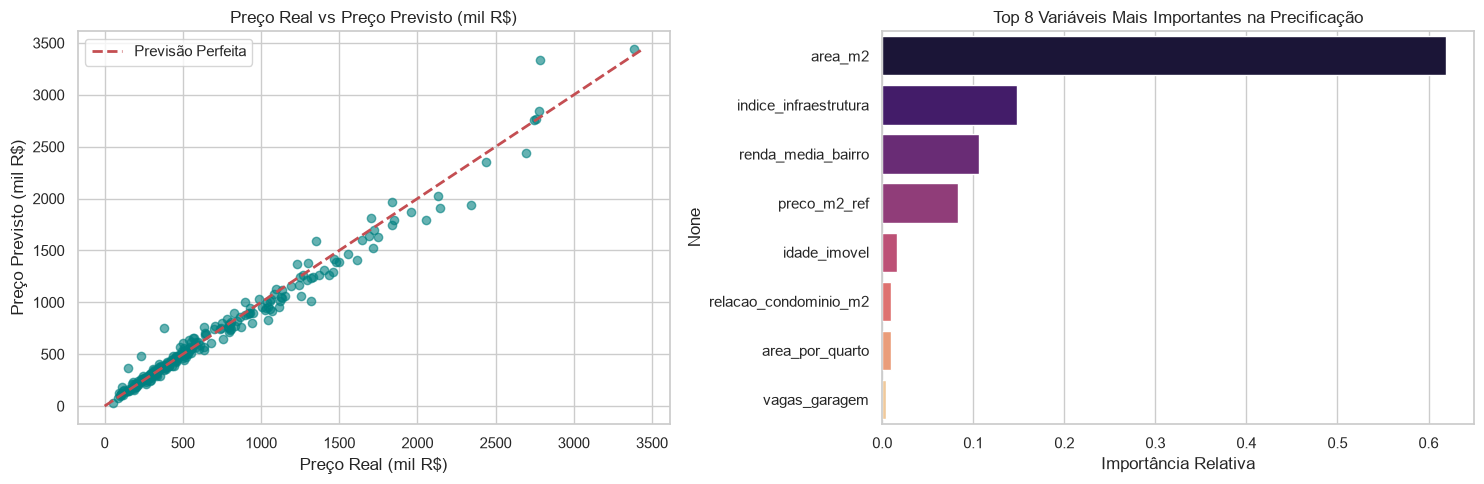


=== 5.3 DECISÃO FINAL ===
DECISÃO: APROVADO PARA IMPLEMENTAÇÃO (Fase 6).
Justificativa: O modelo superou tanto o critério técnico quanto a meta comercial de erro <= 12%.


In [1]:
# ==============================================================================
# FASES 4 E 5: MODELAGEM E AVALIAÇÃO (CRISP-DM - Itens 4.1 a 4.4 e 5.1 a 5.3)
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error

sns.set_theme(style="whitegrid")

# Carregar base tratada da Fase 3
df = pd.read_csv("../data/processed/imoveis_tratado.csv")

# Preparação final para modelagem (One-Hot Encoding nas variáveis categóricas)
df_model = pd.get_dummies(df, columns=["bairro", "tipo"], drop_first=True)

X = df_model.drop(columns=["preco_venda"])
y = df_model["preco_venda"]

# ------------------------------------------------------------------------------
# 4.3 Design de Teste (Partição Treino 80% / Teste 20% + Validação Cruzada 5-Fold)
# ------------------------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("=== 4.3 DESIGN DE TESTE ===")
print(f"Conjunto de Treino: {X_train.shape[0]} registros (80%)")
print(f"Conjunto de Teste:  {X_test.shape[0]} registros (20%)\n")

# ------------------------------------------------------------------------------
# 4.1 Seleção de Técnicas e 4.4 Avaliação Técnica Estatística (Iteração 1)
# ------------------------------------------------------------------------------
modelos = {
    "Regressão Linear (Baseline)": LinearRegression(),
    "Random Forest (Padrão)": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting (Padrão)": GradientBoostingRegressor(random_state=42)
}

resultados = []
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    cv_r2 = cross_val_score(modelo, X_train, y_train, cv=5, scoring="r2").mean()
    
    resultados.append({
        "Modelo": nome,
        "CV R² (Treino)": round(cv_r2, 4),
        "R² (Teste)": round(r2_score(y_test, y_pred), 4),
        "MAE (R$)": round(mean_absolute_error(y_test, y_pred), 2),
        "RMSE (R$)": round(root_mean_squared_error(y_test, y_pred), 2),
        "MAPE (%)": round(mean_absolute_percentage_error(y_test, y_pred) * 100, 2)
    })

# ------------------------------------------------------------------------------
# 4.2 Construção e Iteração (Ajuste de Hiperparâmetros - Iteração 2)
# ------------------------------------------------------------------------------
gb_tunado = GradientBoostingRegressor(
    n_estimators=250, learning_rate=0.05, max_depth=4, random_state=42
)
gb_tunado.fit(X_train, y_train)
y_pred_final = gb_tunado.predict(X_test)
cv_r2_tunado = cross_val_score(gb_tunado, X_train, y_train, cv=5, scoring="r2").mean()

resultados.append({
    "Modelo": "Gradient Boosting (Iteração 2 - Tunado)",
    "CV R² (Treino)": round(cv_r2_tunado, 4),
    "R² (Teste)": round(r2_score(y_test, y_pred_final), 4),
    "MAE (R$)": round(mean_absolute_error(y_test, y_pred_final), 2),
    "RMSE (R$)": round(root_mean_squared_error(y_test, y_pred_final), 2),
    "MAPE (%)": round(mean_absolute_percentage_error(y_test, y_pred_final) * 100, 2)
})

df_resultados = pd.DataFrame(resultados)
print("=== 4.1, 4.2 e 4.4 COMPARATIVO DE MODELOS ===")
display(df_resultados)

# ------------------------------------------------------------------------------
# 5.1 Resultados frente às Metas de Negócio (Impacto Real > Precisão Técnica)
# ------------------------------------------------------------------------------
r2_final = r2_score(y_test, y_pred_final)
mape_final = mean_absolute_percentage_error(y_test, y_pred_final) * 100
mae_final = mean_absolute_error(y_test, y_pred_final)

print("\n=== 5.1 AVALIAÇÃO FRENTE ÀS METAS DA FASE 1 ===")
print(f"Meta Técnica (R² >= 0.80):         {r2_final:.4f} -> {'ATINGIDA' if r2_final >= 0.80 else 'NÃO ATINGIDA'}")
print(f"Meta de Negócio (MAPE <= 12.0%):   {mape_final:.2f}%  -> {'ATINGIDA' if mape_final <= 12.0 else 'NÃO ATINGIDA'}")
print(f"Erro Médio Absoluto em Reais:      R$ {mae_final:,.2f}")

# ------------------------------------------------------------------------------
# 5.2 Revisão de Falhas (Análise de Resíduos e Maiores Erros)
# ------------------------------------------------------------------------------
df_analise = df.loc[X_test.index].copy()
df_analise["preco_previsto"] = y_pred_final
df_analise["erro_pct"] = (np.abs(df_analise["preco_venda"] - df_analise["preco_previsto"]) / df_analise["preco_venda"]) * 100

print("\n=== 5.2 REVISÃO DE FALHAS (ERRO MÉDIO % POR TIPO DE IMÓVEL) ===")
print(df_analise.groupby("tipo")["erro_pct"].mean().round(2))

# Gráficos da Fase 5
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1: Real vs Previsto
axes[0].scatter(y_test / 1000, y_pred_final / 1000, alpha=0.6, color="teal")
limite = max(y_test.max(), y_pred_final.max()) / 1000
axes[0].plot([0, limite], [0, limite], "r--", lw=2, label="Previsão Perfeita")
axes[0].set_title("Preço Real vs Preço Previsto (mil R$)")
axes[0].set_xlabel("Preço Real (mil R$)")
axes[0].set_ylabel("Preço Previsto (mil R$)")
axes[0].legend()

# Gráfico 2: Importância das Variáveis (Top 8)
importancias = pd.Series(gb_tunado.feature_importances_, index=X.columns).sort_values(ascending=False).head(8)
sns.barplot(x=importancias.values, y=importancias.index, ax=axes[1], palette="magma")
axes[1].set_title("Top 8 Variáveis Mais Importantes na Precificação")
axes[1].set_xlabel("Importância Relativa")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 5.3 Decisão Formal: Implementar ou Iterar?
# ------------------------------------------------------------------------------
print("\n=== 5.3 DECISÃO FINAL ===")
if r2_final >= 0.80 and mape_final <= 12.0:
    print("DECISÃO: APROVADO PARA IMPLEMENTAÇÃO (Fase 6).")
    print("Justificativa: O modelo superou tanto o critério técnico quanto a meta comercial de erro <= 12%.")
else:
    print("DECISÃO: RETORNAR À PREPARAÇÃO/MODELAGEM PARA NOVA ITERAÇÃO.")